# Full Pipeline Simulation: LR8_32 coarse classifier + x_processed-CC CAPNetLite (single seed)

`SPLIT_MODE = "2022train20"`: train year **2022**, external test year **2018**.
Runs on physical GPU **3** (the 2018/2022 notebooks use different GPUs so they can run concurrently).

1. **LR8_32** (5-class coarse router: BPSK/MSK/DQPSK/8PSK/QPSK-like) is trained ONCE on the
   `lr8_32` vectors stored in `generated_boi_p96_fft2_pt/` (all 8 signal types). It is a
   deterministic linear model (lbfgs), so there is no seed dependence and exactly one LR is saved.
2. **CAPNetLite** (QPSK-like 4-class; baseline 20/20 channels, 5x5 convs, 3+2 residual blocks,
   GELU) is trained for **one randomly-assigned seed** on the raw complex CC matrices in
   `generated_qpsklike_cc_11x15_boi_p96_fft2_pt/` (built from the UNCLIPPED `x_processed`),
   with `abs -> |C|^(2/n) -> divide by p_boi_inband_signal`. Same training recipe as the
   `...-10seeds` notebooks: AdamW, label smoothing, ReduceLROnPlateau, full 200 epochs, **no
   early stopping**. The best-validation checkpoint is saved and loaded after training (one weight file).
3. **Full 8-class pipeline**, evaluated with the one LR and the trained CAPNetLite model:
   - an LR non-QPSK-like decision is final and cannot be repaired by CAPNetLite;
   - only LR decisions routed to `QPSK-like` can reach CAPNetLite;
   - a true QPSK-like sample misrouted by LR remains the LR error;
   - a non-QPSK-like sample falsely routed to QPSK-like has no QPSK-like CC and uses the
     deterministic `QPSK` fallback; so does a true QPSK-like sample with a missing/invalid CC.
4. Accuracy is reported for CAPNetLite (4-class) and the full 8-class pipeline.
   One combined full-pipeline confusion matrix shows both evaluation years using the
   saved best-validation checkpoint. The random seed is not displayed.

Split: `group_split_70_5_25alter/splits` (group-aware 70/5/25, seed 20260926) for BOTH the LR
and CAPNetLite; the external set is the other year in full. 2018 negative-SNR samples are
excluded upstream and again by the dataset checks.

Saved to `fully_online_pipeline_models/`: `lr8_32_2022train20.joblib` and one CAPNetLite
state dict (`..._2022train20.pt`, without a seed suffix). Per-sample single-seed pipeline results (for SNR-accuracy plots)
plus the single-seed summary are saved to `snr_acc_samples_lr8_32_xproccc_2022train20.pt`.

Note: the LR stage reads every `generated_boi_p96_fft2_pt` file of both years to extract the
32-dim `lr8_32` vectors (the files also hold `x_processed`/`z`), so it is I/O heavy. It requires
the regenerated `boi_p96_fft2_full_v4` files; older v1/v2/v3 files have no `lr8_32` (only `lr8_24`, or nothing) and are rejected.


In [1]:
from pathlib import Path
import sys
import os

# The 2018 and 2022 notebooks use different physical GPUs so both can run at once.
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

# Run with the Jupyter working directory set to this notebook's folder.
BASE_DIR = Path(".")
MODEL_DIR = BASE_DIR / "fully_online_pipeline_models"
FE_PT_ROOT = BASE_DIR / "generated_boi_p96_fft2_pt"
PT_ROOT = BASE_DIR / "generated_qpsklike_cc_11x15_boi_p96_fft2_pt"
ALTER_DIR = BASE_DIR / "group_split_70_5_25alter"
DATASET_ROOT = BASE_DIR / "../../CSPB.ML_dataset"
if str(ALTER_DIR) not in sys.path:
    sys.path.insert(0, str(ALTER_DIR))
from split_utils import ensure_manifests, split_index_sets  # noqa: E402

import gc, math, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score

SPLIT_MODE = "2022train20"
TRAIN_SET_NAME = "2022"
EXT_SET_NAME = "2018"

# CAPNetLite baseline architecture and training recipe (identical to the 10-seed notebooks).
C1 = 20
C2 = 20
KERNEL = 5
N_BLOCKS1 = 3
N_BLOCKS2 = 2
WEIGHT_DECAY = 8e-4
LR = 1.3e-3
BATCH_SIZE = 250
LABEL_SMOOTHING = 0.12
EPOCHS = 200  # no early stopping: training runs all 200 epochs
PLATEAU_PATIENCE = 7
PLATEAU_FACTOR = 0.3

torch.use_deterministic_algorithms(False)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

if not torch.cuda.is_available() or torch.cuda.device_count() != 1:
    raise RuntimeError("Physical CUDA GPU 3 is required; expected exactly one visible CUDA device.")
DEVICE = torch.device("cuda:0")
print("CUDA_VISIBLE_DEVICES:", os.environ["CUDA_VISIBLE_DEVICES"])
print("Visible CUDA device:", torch.cuda.get_device_name(0))
print("DEVICE:", DEVICE)

N_BATCHES = 28
DROP_2018_NEGATIVE_SNR = True

CLASS_NAMES = ["QPSK", "16QAM", "64QAM", "256QAM"]
LABEL_MAP = {"qpsk": 0, "16qam": 1, "64qam": 2, "256qam": 3}
N_CLASSES = len(CLASS_NAMES)

# Columns in the raw 11x15 CC are (n=2: 3), (n=4: 5), (n=6: 7).
CC_COLUMN_ORDERS = torch.tensor([2] * 3 + [4] * 5 + [6] * 7, dtype=torch.float32)
CC_SCALE_EPS = torch.tensor(1e-12, dtype=torch.float32)


def list_fe_files(year: str):
    return [FE_PT_ROOT / f"{year}_batch_{i:02d}_boi_p96_fft2_full.pt" for i in range(1, N_BATCHES + 1)]


def list_cc_files(year: str):
    return [PT_ROOT / f"{year}_batch_{i:02d}_qpsklike_cc_1x11x15_boi_p96_fft2.pt" for i in range(1, N_BATCHES + 1)]


fe_files = {"2018": list_fe_files("2018"), "2022": list_fe_files("2022")}
cc_files = {"2018": list_cc_files("2018"), "2022": list_cc_files("2022")}
for label, files_by_year in [("FE", fe_files), ("CC", cc_files)]:
    for year, files in files_by_year.items():
        missing = [str(p) for p in files if not p.exists()]
        print(f"missing_{label}_{year}:", len(missing), "" if not missing else f"first={missing[0]}")

manifests = ensure_manifests(DATASET_ROOT, ALTER_DIR)
split_indices = split_index_sets(manifests, int(TRAIN_SET_NAME))
print("SPLIT_MODE:", SPLIT_MODE)
for name, idx in split_indices.items():
    print(f"  {name} indices: {len(idx)}")
print("FE_PT_ROOT:", FE_PT_ROOT)
print("CC PT_ROOT:", PT_ROOT)
print("MODEL_DIR:", MODEL_DIR)


CUDA_VISIBLE_DEVICES: 3
Visible CUDA device: NVIDIA GeForce RTX 3090
DEVICE: cuda:0
missing_FE_2018: 0 
missing_FE_2022: 0 
missing_CC_2018: 0 
missing_CC_2022: 0 
SPLIT_MODE: 2022train20
  train indices: 78400
  val indices: 5600
  test indices: 28000
  ext indices: 111632
FE_PT_ROOT: generated_boi_p96_fft2_pt
CC PT_ROOT: generated_qpsklike_cc_11x15_boi_p96_fft2_pt
MODEL_DIR: fully_online_pipeline_models


In [2]:
# =========================
# Stage 1: LR8_32 LogisticRegression coarse classifier (trained once)
# =========================
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

LR_VECTOR_KEY = "lr8_32"
LR_LABEL5_ORDER = ["BPSK", "MSK", "DQPSK", "8PSK", "QPSK-like"]
FULL8_LABEL_ORDER = ["BPSK", "MSK", "DQPSK", "8PSK", "QPSK", "16QAM", "64QAM", "256QAM"]
QPSKLIKE_SIGNAL_TYPES = {"qpsk", "16qam", "64qam", "256qam"}


def label5_from_signal_type(signal_type):
    sig = str(signal_type).strip().lower()
    if sig == "bpsk": return "BPSK"
    if sig == "msk": return "MSK"
    if sig == "dqpsk": return "DQPSK"
    if sig == "8psk": return "8PSK"
    if sig in QPSKLIKE_SIGNAL_TYPES: return "QPSK-like"
    raise ValueError(f"Unsupported signal_type={signal_type!r}")


def label8_from_signal_type(signal_type):
    sig = str(signal_type).strip().lower()
    mapping = {
        "bpsk": "BPSK", "msk": "MSK", "dqpsk": "DQPSK", "8psk": "8PSK",
        "qpsk": "QPSK", "16qam": "16QAM", "64qam": "64QAM", "256qam": "256QAM",
    }
    if sig not in mapping:
        raise ValueError(f"Unsupported signal_type={signal_type!r}")
    return mapping[sig]


def load_lr8_32_vectors(years=("2018", "2022")):
    """Reads lr8_32 from every status=True sample of the boi_p96_fft2_full_v4 files."""
    meta_parts, x_parts = [], []
    feature_names = None
    t0 = time.time()
    for year in years:
        for file_idx, path in enumerate(fe_files[year], start=1):
            pack = torch.load(path, map_location="cpu", weights_only=False)
            if pack.get("version") != "boi_p96_fft2_full_v4" or "lr8_32_feature_names" not in pack:
                raise ValueError(
                    f"{path.name}: version={pack.get('version')!r} has no lr8_32 -- regenerate it with "
                    "pre_BOI+FFT-Generate-*-compact-vectors-final.ipynb first."
                )
            names = list(pack["lr8_32_feature_names"])
            if len(names) != 32:
                raise ValueError(f"{path.name}: expected 32 LR8_32 feature names, got {len(names)}")
            if feature_names is None:
                feature_names = names
            elif feature_names != names:
                raise ValueError(f"LR8_32 feature-name mismatch in {path}")

            rows, vectors = [], []
            n_skipped = 0
            for sample in pack["samples"]:
                if not sample["status"]:
                    n_skipped += 1  # 2018 negative-SNR skip or upstream processing error
                    continue
                meta, truth = sample["meta"], sample["truth"]
                signal_type = str(truth["signal_type"]).strip().lower()
                batch_id = int(meta["batch_id"])
                signal_index = int(meta["signal_index"])
                rows.append({
                    "year": str(year), "batch_id": batch_id, "signal_index": signal_index,
                    "signal_type": signal_type,
                    "label5": label5_from_signal_type(signal_type),
                    "label8": label8_from_signal_type(signal_type),
                    "snr": float(truth["inband_snr_db_label"]),
                    "cc_key": (str(year), batch_id, signal_index),
                })
                vector = np.asarray(sample[LR_VECTOR_KEY], dtype=np.float32)
                if vector.shape != (32,):
                    raise ValueError(f"{path.name} signal {signal_index}: LR8_32 shape={vector.shape}")
                vectors.append(vector)

            meta_parts.append(pd.DataFrame(rows))
            x_parts.append(np.vstack(vectors).astype(np.float32, copy=False))
            print(
                f"LR8_32 load {year} {file_idx:02d}/{len(fe_files[year]):02d} {path.name}: "
                f"rows={len(rows)} skipped_status_false={n_skipped} elapsed={time.time() - t0:.1f}s",
                flush=True,
            )
            del pack
            gc.collect()

    meta_df = pd.concat(meta_parts, ignore_index=True)
    X = np.vstack(x_parts).astype(np.float32, copy=False)
    if DROP_2018_NEGATIVE_SNR:
        keep = ~((meta_df["year"] == "2018") & (meta_df["snr"] < 0))
        dropped = int((~keep).sum())
        if dropped:
            print(f"LR8_32 additionally dropped {dropped} 2018 negative-SNR rows")
        meta_df = meta_df.loc[keep].reset_index(drop=True)
        X = X[keep.to_numpy()]
    X = np.where(np.isfinite(X), X, np.nan).astype(np.float32, copy=False)
    print("LR8_32 rows:", len(meta_df), "X:", X.shape, "features:", len(feature_names))
    print(meta_df["label5"].value_counts().reindex(LR_LABEL5_ORDER))
    return meta_df, X, feature_names


lr_meta_df, X_lr8_32, lr8_32_feature_names = load_lr8_32_vectors()
y_lr5 = lr_meta_df["label5"].astype(str).to_numpy()


def make_lr_masks():
    """Group-split masks by signal_index; ext = the other year in full."""
    year = lr_meta_df["year"]
    idx = lr_meta_df["signal_index"]
    train_mask = (year == TRAIN_SET_NAME) & idx.isin(split_indices["train"])
    val_mask = (year == TRAIN_SET_NAME) & idx.isin(split_indices["val"])
    test_mask = (year == TRAIN_SET_NAME) & idx.isin(split_indices["test"])
    ext_mask = (year == EXT_SET_NAME) & idx.isin(split_indices["ext"])
    return train_mask.to_numpy(), val_mask.to_numpy(), test_mask.to_numpy(), ext_mask.to_numpy()


lr_train_mask, lr_val_mask, lr_test_mask, lr_ext_mask = make_lr_masks()
lr8_32_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, n_jobs=-1, class_weight="balanced", C=3, random_state=None),
)

print("Training LR8_32 coarse classifier...")
t0 = time.time()
lr8_32_model.fit(X_lr8_32[lr_train_mask], y_lr5[lr_train_mask])
print(f"LR8_32 trained in {time.time() - t0:.1f}s")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
LR_MODEL_PATH = MODEL_DIR / f"lr8_32_{SPLIT_MODE}.joblib"
joblib.dump({
    "model": lr8_32_model,
    "split_mode": SPLIT_MODE,
    "split": "group_split_70_5_25alter (seed 20260926)",
    "vector_key": LR_VECTOR_KEY,
    "feature_names": list(lr8_32_feature_names),
    "class_names": list(LR_LABEL5_ORDER),
    "drop_2018_negative_snr": bool(DROP_2018_NEGATIVE_SNR),
    "source_schema": "boi_p96_fft2_full_v4",
}, LR_MODEL_PATH)
print("Saved LR8_32 model to:", LR_MODEL_PATH)

for name, mask in [("train", lr_train_mask), ("val", lr_val_mask), ("same-domain test", lr_test_mask), ("external", lr_ext_mask)]:
    pred = lr8_32_model.predict(X_lr8_32[mask])
    acc = accuracy_score(y_lr5[mask], pred)
    cm = pd.DataFrame(confusion_matrix(y_lr5[mask], pred, labels=LR_LABEL5_ORDER), index=LR_LABEL5_ORDER, columns=LR_LABEL5_ORDER)
    print(f"\nLR8_32 {name}: n={int(mask.sum())} acc={acc*100:.4f}% errors={int((pred != y_lr5[mask]).sum())}")


LR8_32 load 2018 01/28 2018_batch_01_boi_p96_fft2_full.pt: rows=3992 skipped_status_false=8 elapsed=42.8s
LR8_32 load 2018 02/28 2018_batch_02_boi_p96_fft2_full.pt: rows=3984 skipped_status_false=16 elapsed=80.6s
LR8_32 load 2018 03/28 2018_batch_03_boi_p96_fft2_full.pt: rows=3984 skipped_status_false=16 elapsed=118.6s
LR8_32 load 2018 04/28 2018_batch_04_boi_p96_fft2_full.pt: rows=3984 skipped_status_false=16 elapsed=155.6s
LR8_32 load 2018 05/28 2018_batch_05_boi_p96_fft2_full.pt: rows=3992 skipped_status_false=8 elapsed=195.7s
LR8_32 load 2018 06/28 2018_batch_06_boi_p96_fft2_full.pt: rows=3984 skipped_status_false=16 elapsed=231.6s
LR8_32 load 2018 07/28 2018_batch_07_boi_p96_fft2_full.pt: rows=3984 skipped_status_false=16 elapsed=272.6s
LR8_32 load 2018 08/28 2018_batch_08_boi_p96_fft2_full.pt: rows=3984 skipped_status_false=16 elapsed=314.3s
LR8_32 load 2018 09/28 2018_batch_09_boi_p96_fft2_full.pt: rows=3992 skipped_status_false=8 elapsed=348.2s
LR8_32 load 2018 10/28 2018_batch

In [3]:
# =========================
# x_processed raw-CC Warping + Scaling and Dataset (built once)
# =========================
def raw_cc_abs_warp_scale(raw_cc, power):
    """float32: abs -> |C(n,m)|**(2/n) -> divide by p_boi_inband_signal."""
    raw_cc = torch.as_tensor(raw_cc)
    if raw_cc.ndim != 4 or tuple(raw_cc.shape[1:]) != (1, 11, 15):
        raise ValueError(f"Expected raw cc_matrix [N,1,11,15], got {tuple(raw_cc.shape)}")
    if not torch.is_complex(raw_cc):
        raise TypeError(f"Expected complex raw CC, got {raw_cc.dtype}")
    power = torch.as_tensor(power, dtype=torch.float32).reshape(-1)
    if power.shape[0] != raw_cc.shape[0]:
        raise ValueError(f"Power count {power.shape[0]} != CC count {raw_cc.shape[0]}")

    magnitude = torch.abs(raw_cc.to(torch.complex64)).to(torch.float32)
    exponent = (torch.tensor(2.0, dtype=torch.float32) / CC_COLUMN_ORDERS).view(1, 1, 1, 15)
    warped = torch.pow(magnitude, exponent)  # exact zero remains zero
    return warped / (power.view(-1, 1, 1, 1) + CC_SCALE_EPS)


def cc_truth_snr(truth_row):
    truth_row = truth_row or {}
    for key in ("InbandSNRdB", "inband_snr_db_label", "snr_truth_db"):
        if key in truth_row:
            return float(truth_row[key])
    return float("nan")


def load_cc_pack(path):
    pack = torch.load(path, map_location="cpu", weights_only=False)
    if pack.get("power_field") != "p_boi_inband_signal":
        raise ValueError(f"{path.name}: expected power_field='p_boi_inband_signal', got {pack.get('power_field')!r}")
    raw_all = pack["cc_matrix"]
    if raw_all.ndim != 4 or tuple(raw_all.shape[1:]) != (1, 11, 15) or not torch.is_complex(raw_all):
        raise ValueError(f"{path.name}: expected complex cc_matrix [N,1,11,15], got {tuple(raw_all.shape)} {raw_all.dtype}")
    return pack


def valid_cc_rows(pack, year):
    """(valid source indices, postprocessed X) after status/label/power/finite/SNR checks."""
    raw_all = pack["cc_matrix"]
    n = raw_all.shape[0]
    status = torch.as_tensor(pack.get("status", torch.ones(n, dtype=torch.bool))).bool()
    signal_type = [str(s).strip().lower() for s in list(pack["signal_type"])]
    label_ok = torch.tensor([s in LABEL_MAP for s in signal_type], dtype=torch.bool)
    power_all = torch.as_tensor(pack["p_boi_inband_signal"], dtype=torch.float32)
    power_ok = torch.isfinite(power_all) & (power_all > 0)
    raw_ok = torch.isfinite(raw_all).reshape(n, -1).all(dim=1)
    truth_rows = list(pack.get("truth", [{} for _ in range(n)]))
    snr_all = torch.tensor([cc_truth_snr(row) for row in truth_rows], dtype=torch.float32)
    snr_ok = torch.ones(n, dtype=torch.bool)
    if DROP_2018_NEGATIVE_SNR and str(year) == "2018":
        snr_ok = torch.isfinite(snr_all) & (snr_all >= 0)
    valid = status & label_ok & power_ok & raw_ok & snr_ok
    valid_idx = torch.where(valid)[0]
    X = raw_cc_abs_warp_scale(raw_all[valid], power_all[valid])
    scaled_ok = torch.isfinite(X).reshape(X.shape[0], -1).all(dim=1)
    return valid_idx[scaled_ok], X[scaled_ok], signal_type


class QPSKLikeCCDataset(Dataset):
    """Raw complex [N,1,11,15] x_processed CC restricted to a group-split index set."""
    def __init__(self, pt_files, year, allowed_indices):
        allowed = set(int(i) for i in allowed_indices)
        X_list, y_list = [], []
        for p in pt_files:
            pack = load_cc_pack(p)
            valid_idx, X, signal_type = valid_cc_rows(pack, year)
            signal_index = torch.as_tensor(pack["signal_index"]).long()
            in_split = torch.tensor([int(signal_index[i]) in allowed for i in valid_idx.tolist()], dtype=torch.bool)
            X = X[in_split]
            keep_idx = valid_idx[in_split]
            y = torch.tensor([LABEL_MAP[signal_type[i]] for i in keep_idx.tolist()], dtype=torch.long)
            X_list.append(X)
            y_list.append(y)
            del pack
        self.X = torch.cat(X_list, dim=0).to(torch.float32)
        self.y = torch.cat(y_list, dim=0).long()
        if tuple(self.X.shape[1:]) != (1, 11, 15):
            raise ValueError(f"Unexpected final dataset shape: {tuple(self.X.shape)}")

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


ds_train = QPSKLikeCCDataset(cc_files[TRAIN_SET_NAME], TRAIN_SET_NAME, split_indices["train"])
ds_val = QPSKLikeCCDataset(cc_files[TRAIN_SET_NAME], TRAIN_SET_NAME, split_indices["val"])
ds_test = QPSKLikeCCDataset(cc_files[TRAIN_SET_NAME], TRAIN_SET_NAME, split_indices["test"])
ds_ext = QPSKLikeCCDataset(cc_files[EXT_SET_NAME], EXT_SET_NAME, split_indices["ext"])
print("Train/val/test/ext:", ds_train.X.shape, ds_val.X.shape, ds_test.X.shape, ds_ext.X.shape)
for name, ds in [("train", ds_train), ("val", ds_val), ("test", ds_test), ("ext", ds_ext)]:
    counts = {CLASS_NAMES[c]: int((ds.y == c).sum()) for c in range(N_CLASSES)}
    print(f"  {name}: {counts}")


Train/val/test/ext: torch.Size([39200, 1, 11, 15]) torch.Size([2800, 1, 11, 15]) torch.Size([14000, 1, 11, 15]) torch.Size([55816, 1, 11, 15])
  train: {'QPSK': 9800, '16QAM': 9800, '64QAM': 9800, '256QAM': 9800}
  val: {'QPSK': 700, '16QAM': 700, '64QAM': 700, '256QAM': 700}
  test: {'QPSK': 3500, '16QAM': 3500, '64QAM': 3500, '256QAM': 3500}
  ext: {'QPSK': 13954, '16QAM': 13954, '64QAM': 13954, '256QAM': 13954}


## Train CAPNetLite: single seed

Train once for all 200 epochs; save and load the best-validation checkpoint.


In [44]:
# ---------------------------------------------------------------------------
# CAPNetLite: a small FPGA-friendly ResNet-style CNN (baseline, GELU).
#   - a single shared trunk + one small FC head
#   - static-padding convs, one channel width per stage
#   - BatchNorm folds into the preceding conv at inference
# ---------------------------------------------------------------------------
class ResBlock(nn.Module):
    def __init__(self, ch, kernel=3):
        super().__init__()
        pad = kernel // 2
        self.conv1 = nn.Conv2d(ch, ch, kernel_size=kernel, stride=1, padding=pad, bias=False)
        self.bn1 = nn.BatchNorm2d(ch)
        self.conv2 = nn.Conv2d(ch, ch, kernel_size=kernel, stride=1, padding=pad, bias=False)
        self.bn2 = nn.BatchNorm2d(ch)

    def forward(self, x):
        identity = x
        out = F.gelu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + identity
        return F.gelu(out)


class Stage(nn.Module):
    def __init__(self, ch, n_blocks, kernel):
        super().__init__()
        self.blocks = nn.ModuleList([ResBlock(ch, kernel) for _ in range(n_blocks)])

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        return x


class CAPNetLite(nn.Module):
    def __init__(self, n_classes=4, c1=20, c2=20, kernel=5, n_blocks1=3, n_blocks2=2):
        super().__init__()
        pad = kernel // 2
        self.stem = nn.Conv2d(1, c1, kernel_size=kernel, stride=1, padding=pad, bias=False)
        self.stem_bn = nn.BatchNorm2d(c1)
        self.block1 = Stage(c1, n_blocks1, kernel)
        self.down = nn.Conv2d(c1, c2, kernel_size=kernel, stride=(1, 2), padding=pad, bias=False)
        self.down_bn = nn.BatchNorm2d(c2)
        self.block2 = Stage(c2, n_blocks2, kernel)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(c2, n_classes)

    def forward(self, x):
        x = F.gelu(self.stem_bn(self.stem(x)))
        x = self.block1(x)
        x = F.gelu(self.down_bn(self.down(x)))
        x = self.block2(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)


def build_model():
    return CAPNetLite(n_classes=N_CLASSES, c1=C1, c2=C2, kernel=KERNEL,
                      n_blocks1=N_BLOCKS1, n_blocks2=N_BLOCKS2).to(DEVICE)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)


@torch.no_grad()
def eval_one(model, loader):
    model.eval()
    ys, ps, losses = [], [], []
    for X, y in loader:
        X = X.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        logits = model(X)
        losses.append(criterion(logits, y).item())
        ys.append(y.cpu())
        ps.append(logits.argmax(dim=1).cpu())
    y_true = torch.cat(ys).numpy()
    y_pred = torch.cat(ps).numpy()
    return float(np.mean(losses)), float(accuracy_score(y_true, y_pred)), y_true, y_pred


def capnet_model_path():
    return MODEL_DIR / (
        f"capnet_lite_lr8_32_xprocrawcc_warpscale_k{KERNEL}_c{C1}_{C2}_nb{N_BLOCKS1}_{N_BLOCKS2}"
        f"_{SPLIT_MODE}.pt"
    )


val_loader = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
ext_loader = DataLoader(ds_ext, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


def train_one_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    loader_generator = torch.Generator()
    loader_generator.manual_seed(seed)
    train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                              pin_memory=True, generator=loader_generator)

    model = build_model()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=PLATEAU_FACTOR, patience=PLATEAU_PATIENCE, min_lr=1e-5
    )

    best_val_acc, best_epoch, best_state = -1.0, -1, None
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses, correct, total = [], 0, 0
        for X, y in train_loader:
            X = X.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            correct += (logits.argmax(dim=1) == y).sum().item()
            total += y.numel()
        va_loss, va_acc, _, _ = eval_one(model, val_loader)
        if va_acc > best_val_acc + 1e-4:
            best_val_acc, best_epoch = va_acc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if epoch % 20 == 0 or epoch == 1:
            print(f"  epoch {epoch:03d} | lr {optimizer.param_groups[0]['lr']:.2e} | "
                  f"train {np.mean(losses):.4f}/{correct / total * 100:5.2f}% | val {va_loss:.4f}/{va_acc * 100:5.2f}% | "
                  f"best {best_val_acc * 100:5.2f}%@{best_epoch}", flush=True)
        scheduler.step(va_acc)
        # No early stopping: always runs all EPOCHS.

    if best_state is None:
        raise RuntimeError("No best validation state was captured.")
    path = capnet_model_path()
    torch.save(best_state, path)

    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True), strict=True)
    _, same_acc, y_same, p_same = eval_one(model, test_loader)
    _, ext_acc, y_ext, p_ext = eval_one(model, ext_loader)
    labels = list(range(N_CLASSES))
    result = {
        "seed": seed, "best_val_acc": best_val_acc, "best_epoch": best_epoch,
        "same_acc": same_acc, "ext_acc": ext_acc,
        "same_cm": confusion_matrix(y_same, p_same, labels=labels),
        "ext_cm": confusion_matrix(y_ext, p_ext, labels=labels),
        "model_path": str(path), "state": best_state, "train_minutes": (time.time() - t0) / 60.0,
    }
    del model, optimizer, scheduler
    torch.cuda.empty_cache()
    return result


MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f"CAPNetLite params: {count_params(build_model()):,d}")

seed = random.SystemRandom().randrange(1, 1_000_000)
SEEDS = [seed]
r = train_one_seed(seed)
print(f"best_val={r['best_val_acc']*100:.3f}%@{r['best_epoch']} "
      f"same={r['same_acc']*100:.3f}% ext={r['ext_acc']*100:.3f}% "
      f"time={r['train_minutes']:.1f} min")
seed_results = [r]


CAPNetLite params: 111,064
  epoch 001 | lr 1.30e-03 | train 0.7637/75.15% | val 1.6413/49.54% | best 49.54%@1
  epoch 020 | lr 3.90e-04 | train 0.5838/88.02% | val 0.6243/86.04% | best 87.64%@17
  epoch 040 | lr 3.51e-05 | train 0.5681/89.14% | val 0.5864/87.29% | best 88.57%@30
  epoch 060 | lr 3.51e-05 | train 0.5668/89.23% | val 0.5693/88.61% | best 89.68%@55
  epoch 080 | lr 1.00e-05 | train 0.5646/89.38% | val 0.5599/89.50% | best 89.68%@55
  epoch 100 | lr 1.00e-05 | train 0.5643/89.45% | val 0.5587/89.43% | best 89.79%@99
  epoch 120 | lr 1.00e-05 | train 0.5642/89.52% | val 0.5574/89.71% | best 89.82%@105
  epoch 140 | lr 1.00e-05 | train 0.5632/89.47% | val 0.5576/89.68% | best 89.82%@105
  epoch 160 | lr 1.00e-05 | train 0.5634/89.52% | val 0.5600/89.61% | best 89.82%@105
  epoch 180 | lr 1.00e-05 | train 0.5627/89.59% | val 0.5568/89.79% | best 89.89%@173
  epoch 200 | lr 1.00e-05 | train 0.5623/89.51% | val 0.5564/89.75% | best 89.93%@195
best_val=89.929%@195 same=89.029% 

## Full 8-class pipeline: LR8_32 + the trained CAPNetLite model

Load the saved CAPNetLite checkpoint and evaluate both test sets.
LR routing errors cannot be corrected by the CNN.


In [45]:
def load_qpsklike_cc_lookup(files_by_year):
    """Map postprocessed raw CC by (year, batch_id, signal_index)."""
    cc_lookup = {}
    for year, files in files_by_year.items():
        for path in files:
            pack = load_cc_pack(path)
            valid_idx, X, _ = valid_cc_rows(pack, year)
            signal_indices = torch.as_tensor(pack["signal_index"]).long()
            batch_id = int(pack["batch_id"])
            for out_i, src_i in enumerate(valid_idx.tolist()):
                cc_lookup[(str(year), batch_id, int(signal_indices[src_i]))] = X[out_i]
            del pack
    return cc_lookup


cc_lookup = load_qpsklike_cc_lookup(cc_files)
print("CC lookup entries:", len(cc_lookup))


def prepare_pipeline(mask, name):
    """LR routing for one evaluation set; independent of the CAPNetLite seed."""
    rows = lr_meta_df.loc[mask].copy().reset_index(drop=True)
    pred5 = lr8_32_model.predict(X_lr8_32[mask])
    base_pred = np.empty(len(rows), dtype=object)
    route = np.empty(len(rows), dtype=object)
    nn_positions, nn_tensors, n_missing_cc = [], [], 0
    for i, (row, coarse_pred) in enumerate(zip(rows.itertuples(index=False), pred5)):
        if coarse_pred != "QPSK-like":
            base_pred[i], route[i] = coarse_pred, "lr_non_qpsklike"
        elif row.label5 != "QPSK-like":
            base_pred[i], route[i] = "QPSK", "lr_false_qpsklike_forced_qpsk"
        elif row.cc_key not in cc_lookup:
            base_pred[i], route[i] = "QPSK", "true_qpsklike_missing_cc_forced_qpsk"
            n_missing_cc += 1
        else:
            route[i] = "lr_qpsklike_capnetlite"
            nn_positions.append(i)
            nn_tensors.append(cc_lookup[row.cc_key])
    X_nn = torch.stack(nn_tensors, dim=0) if nn_tensors else torch.empty(0, 1, 11, 15)
    return {"name": name, "rows": rows, "pred5": pred5, "base_pred": base_pred, "route": route,
            "nn_positions": nn_positions, "X_nn": X_nn, "n_missing_cc": n_missing_cc}


@torch.no_grad()
def predict_capnetlite(model, X_tensor):
    if X_tensor.numel() == 0:
        return np.asarray([], dtype=np.int64)
    loader = DataLoader(torch.utils.data.TensorDataset(X_tensor), batch_size=BATCH_SIZE, shuffle=False)
    model.eval()
    preds = [model(X_batch.to(DEVICE, non_blocking=True)).argmax(dim=1).cpu() for (X_batch,) in loader]
    return torch.cat(preds).numpy()


def evaluate_pipeline(prep, model):
    rows = prep["rows"]
    final_pred = prep["base_pred"].copy()
    for pos, pred_idx in zip(prep["nn_positions"], predict_capnetlite(model, prep["X_nn"])):
        final_pred[pos] = CLASS_NAMES[int(pred_idx)]
    true5 = rows["label5"].astype(str).to_numpy()
    true8 = rows["label8"].astype(str).to_numpy()
    pred5 = prep["pred5"]
    cm8 = pd.DataFrame(confusion_matrix(true8, final_pred, labels=FULL8_LABEL_ORDER),
                       index=FULL8_LABEL_ORDER, columns=FULL8_LABEL_ORDER)
    true_qpsklike, lr_qpsklike = true5 == "QPSK-like", pred5 == "QPSK-like"
    summary = {
        "name": prep["name"], "n": int(len(rows)),
        "lr5_acc_percent": float(accuracy_score(true5, pred5) * 100),
        "full8_acc_percent": float(accuracy_score(true8, final_pred) * 100),
        "full8_errors": int((final_pred != true8).sum()),
        "nn_used": int(len(prep["nn_positions"])),
        "true_qpsklike_lr_non_qpsklike": int((true_qpsklike & ~lr_qpsklike).sum()),
        "non_qpsklike_lr_qpsklike_forced_qpsk": int((~true_qpsklike & lr_qpsklike).sum()),
        "missing_cc_forced_qpsk": int(prep["n_missing_cc"]),
    }
    details = rows.assign(pred5=pred5, pred8=final_pred, route=prep["route"])
    return summary, cm8, details


prep_same = prepare_pipeline(lr_test_mask, f"{TRAIN_SET_NAME} same-domain test")
prep_ext = prepare_pipeline(lr_ext_mask, f"{EXT_SET_NAME} external test")

eval_model = build_model()
r = seed_results[0]
eval_model.load_state_dict(torch.load(r["model_path"], map_location=DEVICE, weights_only=True), strict=True)
r["pipe_same"] = evaluate_pipeline(prep_same, eval_model)
r["pipe_ext"] = evaluate_pipeline(prep_ext, eval_model)

seed_df = pd.DataFrame([{
    "seed": r["seed"],
    "best_val_acc%": r["best_val_acc"] * 100,
    "capnet_same%": r["same_acc"] * 100,
    "capnet_ext%": r["ext_acc"] * 100,
    "full8_same%": r["pipe_same"][0]["full8_acc_percent"],
    "full8_ext%": r["pipe_ext"][0]["full8_acc_percent"],
} for r in seed_results])
metric_cols = ["best_val_acc%", "capnet_same%", "capnet_ext%", "full8_same%", "full8_ext%"]
# Preserve the saved summary schema; the single-run population std is zero.
stats_df = pd.DataFrame({"mean": seed_df[metric_cols].mean(), "std": seed_df[metric_cols].std(ddof=0)}).T

lr_summary_same, lr_summary_ext = seed_results[0]["pipe_same"][0], seed_results[0]["pipe_ext"][0]
print(f"LR8_32 (single model) 5-class acc: "
      f"same={lr_summary_same['lr5_acc_percent']:.4f}% ext={lr_summary_ext['lr5_acc_percent']:.4f}%")
display(seed_df[metric_cols].round(3))


CC lookup entries: 111816
LR8_32 (single model) 5-class acc: same=100.0000% ext=99.8620%


,best_val_acc%,capnet_same%,capnet_ext%,full8_same%,full8_ext%
0,89.929,89.029,82.297,94.514,91.068


## Single trained model: combined confusion matrix


In [46]:
best = seed_results[0]
BEST_SEED = best["seed"]
BEST_MODEL_PATH = best["model_path"]

for key in ("pipe_same", "pipe_ext"):
    summary, cm8, details = best[key]
    print(summary["name"])
    display(pd.Series(details["route"]).value_counts().rename_axis("route").to_frame("count"))


2022 same-domain test


,count
route,
lr_non_qpsklike,14000
lr_qpsklike_capnetlite,14000


2018 external test


,count
route,
lr_non_qpsklike,55958
lr_qpsklike_capnetlite,55673
lr_false_qpsklike_forced_qpsk,1


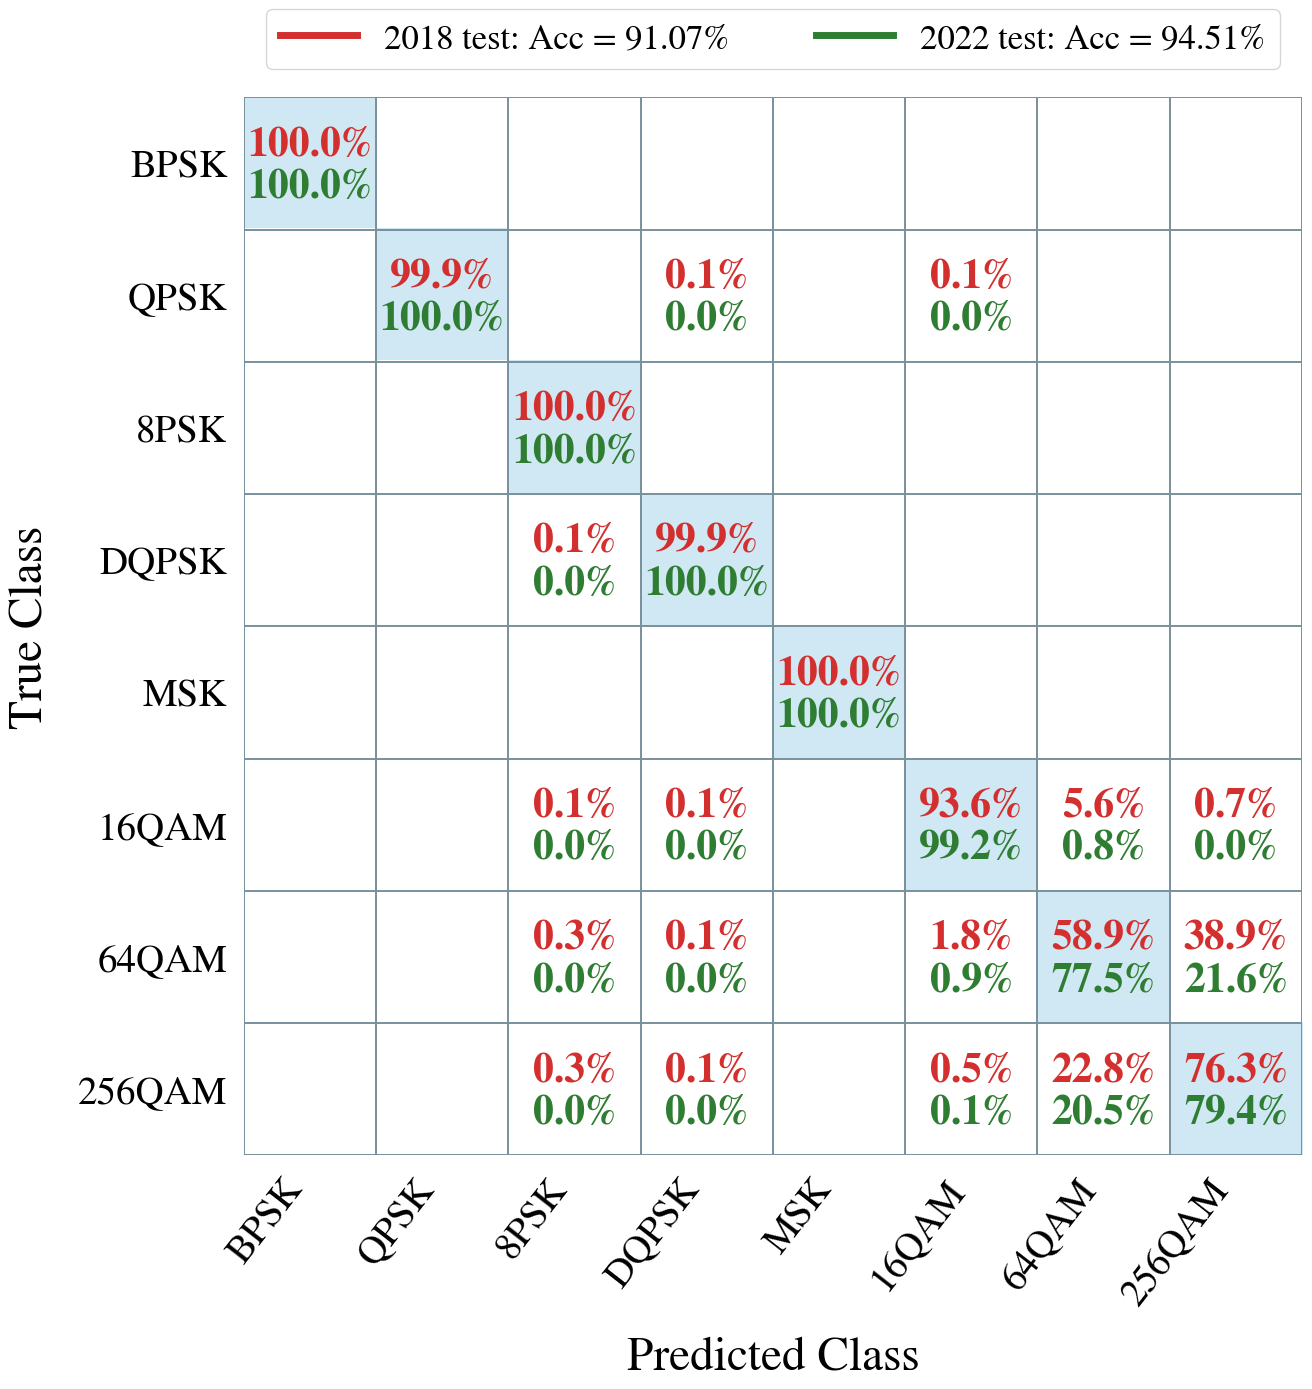

In [47]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})


def row_normalize_cm(cm):
    cm = np.asarray(cm, dtype=np.float64)
    row_sum = cm.sum(axis=1, keepdims=True)
    row_sum[row_sum == 0] = 1.0
    return cm / row_sum * 100.0


def plot_combined_confusion(cm_2018, cm_2022, acc_2018, acc_2022, class_names, save_path=None):
    cm_2018_pct = row_normalize_cm(cm_2018)
    cm_2022_pct = row_normalize_cm(cm_2022)
    n_classes = len(class_names)

    # Light blue diagonal cells, white off-diagonal cells.
    background = np.eye(n_classes)
    cmap = ListedColormap(["#FFFFFF", "#CFE8F3"])

    fig, ax = plt.subplots(figsize=(16, 14))
    ax.imshow(background, cmap=cmap, vmin=0, vmax=1, interpolation="nearest", aspect="equal")

    ax.set_xticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.grid(which="minor", color="#78909C", linestyle="-", linewidth=1.4)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))
    ax.set_xticklabels(class_names, rotation=52, ha="right", fontsize=28)
    ax.set_yticklabels(class_names, fontsize=28)
    ax.set_xlabel("Predicted Class", fontsize=34, labelpad=18)
    ax.set_ylabel("True Class", fontsize=34, labelpad=18)

    # Two percentages per cell; blank when both display as 0.0%.
    for i in range(n_classes):
        for j in range(n_classes):
            value_2018 = cm_2018_pct[i, j]
            value_2022 = cm_2022_pct[i, j]
            if round(value_2018, 1) == 0.0 and round(value_2022, 1) == 0.0:
                continue
            ax.text(j, i - 0.14, f"{value_2018:.1f}%", ha="center", va="center",
                    color="#D32F2F", fontsize=30, fontweight="bold")
            ax.text(j, i + 0.18, f"{value_2022:.1f}%", ha="center", va="center",
                    color="#2E7D32", fontsize=30, fontweight="bold")

    legend_handles = [
        Line2D([0], [0], color="#D32F2F", linewidth=5, label=f"2018 test: Acc = {acc_2018:.2f}%"),
        Line2D([0], [0], color="#2E7D32", linewidth=5, label=f"2022 test: Acc = {acc_2022:.2f}%"),
    ]
    ax.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2,
              frameon=True, fontsize=25, handlelength=2.2, columnspacing=2.5)

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="major", length=0, pad=12)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=600, bbox_inches="tight", facecolor="white")
    plt.show()


# Single-model full-pipeline CMs, combined into one figure for both evaluation years.
result_by_year = {}
for key in ("pipe_same", "pipe_ext"):
    summary, cm8, details = best[key]
    test_years = details["year"].astype(str).unique()
    if len(test_years) != 1:
        raise ValueError(f"Expected one test year, found {test_years}")
    result_by_year[test_years[0]] = {"summary": summary, "cm": cm8}
if "2018" not in result_by_year or "2022" not in result_by_year:
    raise KeyError("Both 2018 and 2022 results are required to draw the combined CM.")

PLOT_CLASS_ORDER = ["BPSK", "QPSK", "8PSK", "DQPSK", "MSK", "16QAM", "64QAM", "256QAM"]
cm_2018 = result_by_year["2018"]["cm"].reindex(index=PLOT_CLASS_ORDER, columns=PLOT_CLASS_ORDER, fill_value=0)
cm_2022 = result_by_year["2022"]["cm"].reindex(index=PLOT_CLASS_ORDER, columns=PLOT_CLASS_ORDER, fill_value=0)

plot_combined_confusion(
    cm_2018=cm_2018.to_numpy(),
    cm_2022=cm_2022.to_numpy(),
    acc_2018=result_by_year["2018"]["summary"]["full8_acc_percent"],
    acc_2022=result_by_year["2022"]["summary"]["full8_acc_percent"],
    class_names=PLOT_CLASS_ORDER,
    save_path=None,
)


In [48]:
# Save single-seed per-sample full-pipeline results (for SNR-accuracy plotting) and summary.
save_data = {
    "version": "lr8_32_xprocrawcc_warpscale_capnetlite_1seed_v1",
    "split_mode": SPLIT_MODE,
    "split": "group_split_70_5_25alter (seed 20260926)",
    "lr_model_path": str(LR_MODEL_PATH),
    "seeds": list(SEEDS),
    "capnet_model_paths": {r["seed"]: r["model_path"] for r in seed_results},
    "best_seed": int(BEST_SEED),
    "best_seed_criterion": "single trained seed; best-validation checkpoint",
    "capnet_model_path": str(BEST_MODEL_PATH),
    "cc_postprocess": "abs -> magnitude**(2/order) -> divide by p_boi_inband_signal (x_processed CC)",
    "seed_summary": seed_df.to_dict(orient="list"),
    "seed_stats": {col: {"mean": float(stats_df.loc["mean", col]), "std": float(stats_df.loc["std", col])}
                   for col in metric_cols},
    "results": {},
}

for key in ("pipe_same", "pipe_ext"):
    summary, cm8, details = best[key]
    test_year = details["year"].astype(str).unique()[0]
    save_data["results"][test_year] = {
        "result_name": summary["name"],
        "test_year": test_year,
        "snr": torch.tensor(details["snr"].to_numpy(dtype=np.float32)),
        "true_type": details["label8"].astype(str).tolist(),
        "pred_type": details["pred8"].astype(str).tolist(),
        "route": details["route"].astype(str).tolist(),
        "overall_accuracy": summary["full8_acc_percent"] / 100.0,
        "summary": dict(summary),
    }

save_path = BASE_DIR / f"snr_acc_samples_lr8_32_xproccc_{SPLIT_MODE}.pt"
torch.save(save_data, save_path)
print("Saved:", save_path)
for year, data in save_data["results"].items():
    print(year, "samples =", len(data["true_type"]), "accuracy =", f'{data["overall_accuracy"] * 100:.2f}%')


Saved: snr_acc_samples_lr8_32_xproccc_2022train20.pt
2022 samples = 28000 accuracy = 94.51%
2018 samples = 111632 accuracy = 91.07%
